# Remote Sensing on VICTOR Lab
<br/>
This notebook provides various methods to analyze the same eruption event using remote sensing data, where default values correspond to eruptions at the Sundhnúkur volcano in Iceland
in March and May of 2024. 
Here you will find workflows to detect thermal anomalies, vegitative disturbance, and sulfur dioxide emissions.


Code for Parts 1 & 2 was written by Sam Krasnoff (VICTOR team software engineer, Columbia LDEO) in collaboration with Grace Bato (NASA JPL). 
Code in Part 3 was written by Claudia Corradino (INGV Catania) -- see reference paper below.


Corradino, C., Jouve, P., La Spina, A., & Del Negro, C. (2024). Monitoring Earth's atmosphere with Sentinel-5 TROPOMI and Artificial Intelligence: Quantifying volcanic SO2 emissions. Remote Sensing of Environment, 315, 114463.

<h2>Part 1: Detecting Thermal Anomalies</h2>

NASA’s MODIS (Moderate Resolution Imaging Spectroradiometer), collecting data from the Terra and Aqua satellites, can be used to detect thermal anomalies.
For volcanologists, this type of remote sensing data can be used to detect volcanic activity. Read more about MODIS here:
https://www.earthdata.nasa.gov/data/instruments/modis

<h3>Step 1:  Import Necessary Libraries & Define Helper Functions</h3>

Run this cell to ensure you have the necessary tools downloaded to run the code.

In [1]:
# Import packages
import pandas as pd
import cartopy
import matplotlib.pyplot as plt
import numpy as np
import sys
import cartopy.crs as ccrs
import cartopy.feature as cfeature
sys.path.insert(0,"/home/jovyan/shared/Libraries")
import victor

MAP_KEY = 'adedf1a21791fe0e126299ba9dab98f0'

<h3>Step 2: Specify spatial and temporal parameters</h3>

Enter coordinate boundaries for your volcano of interest. Identify a time window for your analysis, and enter the first day of the window in YYYY-MM-DD format as your "date" variable.
Enter the total number of days in your time window as the "days" variable. 

In [2]:
# Bounds: Enter in the format min_long, max_long, min_lat, mat_lat // Note that coordinates are currently set to map eruption events at Sundhnúkur
bounds = [-22.6,-21.9,63.7, 63.9]

# Number of days following the start date for which to gather data
days = 7

# Start Date - YYYY-MM-DD format. Leave as none to start at current day
date = "2024-05-29"

<h3>Step 3: Run the search and plot results</h3>

The spatial and temporal paramters you inputted in Step 2 are used here to search the NASA database for thermal signature data.
The plot displays Fire Radiative Power, or energy released by active "fires." In our case, the heat given off by volcanic activity is detected. Read more about fire radiative power here: https://www.earthdata.nasa.gov/dashboard/data-catalog/la-fires-frp

In [3]:
# Use parameters to search NASA database

#
# The FIRMS data server only allows up to 5 days of data per request, so to support
# any value of `days`, the requested window is split into chunks of at most 5 days
# and queried one chunk at a time, working forward from the first day of
# the window. Each chunk's results are combined into a single dataframe at the end.
MAX_DAYS_PER_REQUEST = 5

if date is not None:
    start_date = pd.Timestamp(date)
else:
    start_date = pd.Timestamp.today().normalize() - pd.Timedelta(days=days - 1)

chunks = []
chunk_start = start_date
days_remaining = days

while days_remaining > 0:
    chunk_days = min(MAX_DAYS_PER_REQUEST, days_remaining)
    chunk_str = chunk_start.strftime("%Y-%m-%d")

    try:
        chunk_data = victor.get_firms_data(MAP_KEY, bounds, chunk_days, chunk_str)
        if chunk_data is not None and len(chunk_data) > 0:
            chunks.append(chunk_data)
        print(f"{chunk_str} (+{chunk_days}d): {0 if chunk_data is None else len(chunk_data)} rows")
    except Exception as e:
        print(f"Request failed for {chunk_str} ({chunk_days}d): {e}")

    # Move FORWARD to the next window
    chunk_start += pd.Timedelta(days=chunk_days)
    days_remaining -= chunk_days

# Combine all chunks into a single dataframe, dropping any duplicate detections
# that can occur at the boundary between two chunks
if chunks:
    data = pd.concat(chunks, ignore_index=True).drop_duplicates().reset_index(drop=True)
    print(f"Retrieved {len(data)} detections covering {days} day(s) from {start_date:%Y-%m-%d}.")
else:
    data = pd.DataFrame()
    print("No data returned. Check the date range, source, and API key.")

2024-05-29 (+5d): 72 rows
2024-06-03 (+2d): 154 rows
Retrieved 226 detections covering 7 day(s) from 2024-05-29.


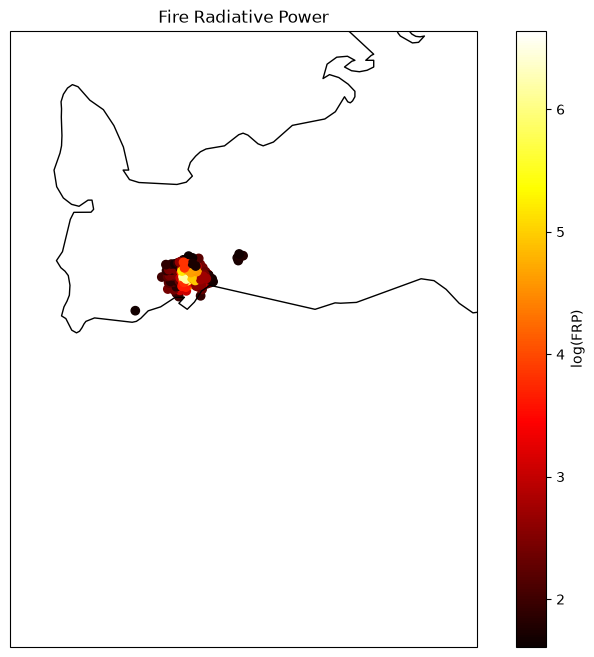

In [4]:
# Plot thermal anomalies
fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.Mercator())

# Set map extent
ax.set_extent([
    bounds[0] - .25,  # min lon
    bounds[1] + .25,  # max lon
    bounds[2] - .25,  # min lat
    bounds[3] + .25   # max lat
], crs=ccrs.PlateCarree())

# Coastlines and country borders
ax.coastlines()
ax.add_feature(cfeature.BORDERS)

# Scatter plot
sc = ax.scatter(
    data.longitude,
    data.latitude,
    # s=data.frp,                 # marker size
    c=np.log(data.frp),         # marker color
    cmap="hot",
    transform=ccrs.PlateCarree()
)

plt.colorbar(sc, ax=ax, label="log(FRP)")
plt.title("Fire Radiative Power")
plt.show()

<h3>Step 4: Plot Daily Total Fire Radiative Power</h3>

The map above shows each individual detection. The scatterplot below summarizes thermal activity over time by summing the total FRP (Fire Radiative Power) detected each day.

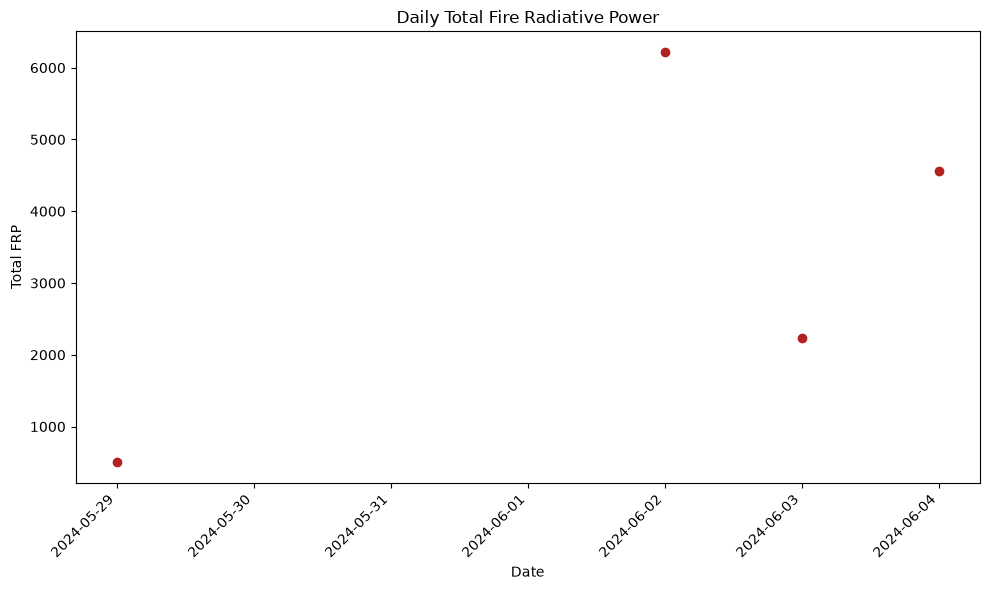

In [5]:
# Sum FRP per unique acquisition day, then plot as a scatterplot
daily_frp = data.groupby('acq_date', as_index=False)['frp'].sum().sort_values('acq_date')
daily_frp['acq_date'] = pd.to_datetime(daily_frp['acq_date'])

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(daily_frp['acq_date'], daily_frp['frp'], color='firebrick')

ax.set_xlabel('Date')
ax.set_ylabel('Total FRP')
ax.set_title('Daily Total Fire Radiative Power')
fig.autofmt_xdate(rotation=45)
plt.tight_layout()
plt.show()


<h2>Part 2: Lava Flow Emplacement</h2>

In this part you will access vegitative disturbance data from NASA's OPERA Project. You will need a NASA Earthdata account to complete this section.
Sign up for an account here: 
https://urs.earthdata.nasa.gov/users/new

Read more about the OPERA project here:
https://www.jpl.nasa.gov/go/opera/about-opera/

<h3>Step 1: Import Necessary Libraries & Define Helper Functions</h3>

Run these cells to ensure necessary tools are downloaded and helper functions are defined for future use.

In [1]:
# Import packages

%load_ext autoreload
%autoreload 2

import os
from netrc import netrc
from subprocess import Popen
from platform import system
from getpass import getpass

from pystac_client import Client  

import json

import matplotlib.pyplot as plt
from matplotlib import cm
from datetime import datetime

from shapely.geometry import box
from shapely.geometry import shape
from shapely.ops import transform
from shapely import wkt
from pyproj import Transformer

import numpy as np
import pandas as pd
import geopandas as gpd

import rioxarray as rxr
import xarray as xr
import rasterio as rio

from osgeo import gdal

import pyproj
from pyproj import Proj

import geoviews as gv
import hvplot.xarray
import holoviews as hv
hv.extension('bokeh')
gv.extension('bokeh', 'matplotlib')

import sys
sys.path.append('./')
from src.dist_utils import intersection_percent, colorize, getbasemaps, transform_data_for_folium

import leafmap
from shapely.geometry import box

import warnings
warnings.filterwarnings('ignore')

In [2]:
# Define helper functions

def stack_bands(bandpath:str, bandlist:list): 
    '''
    Returns geocube with three bands stacked into one multi-dimensional array.
            Parameters:
                    bandpath (str): Path to bands that should be stacked
                    bandlist (list): Three bands that should be stacked
            Returns:
                    bandStack (xarray Dataset): Geocube with stacked bands
                    crs (int): Coordinate Reference System corresponding to bands

   '''
    bandStack = []; bandS = []; bandStack_ = [];
    for i,band in enumerate(bandlist):
        if i==0:
            print(f"{bandpath%band}")
            bandStack_ = rxr.open_rasterio(bandpath%band)
            crs = bandStack_.rio.crs.to_epsg()
            bandStack = bandStack_.squeeze(drop=True)
            bandStack = bandStack.to_dataset(name='z')
            bandStack.coords['band'] = i+1
            bandStack = bandStack.rename({'x':'longitude', 'y':'latitude', 'band':'band'})
            bandStack = bandStack.expand_dims(dim='band')  
        else:
            bandS = rxr.open_rasterio(bandpath%band)
            bandS = bandS.squeeze(drop=True)
            bandS = bandS.to_dataset(name='z')
            bandS.coords['band'] = i+1
            bandS = bandS.rename({'x':'longitude', 'y':'latitude', 'band':'band'})
            bandS = bandS.expand_dims(dim='band')
            bandStack = xr.concat([bandStack, bandS], dim='band')
    return bandStack, crs

def read_dist(tiffile):
    print(f"{tiffile}")
    dat = rxr.open_rasterio(tiffile)
    epsg = dat.rio.crs.to_proj4()
    dat.closed
    
    return dat, epsg

def read_dist_ts(filepaths, time_coords):
    '''
    Opens each file in filepaths and stacks them along a new "time" dimension.
    Files that don't exist on the server (common for granules near the edge
    of a large bounding box, or dates where OPERA DIST-ALERT processing
    didn't run) are skipped with a warning and time_coords entries are dropped to match.
    '''
    data_arrays = []
    kept_time_coords = []
    skipped = []
    for i, fp in enumerate(filepaths):
        try:
            da = rxr.open_rasterio(fp)
            data_arrays.append(da)
            kept_time_coords.append(time_coords[i])
        except Exception as e:
            skipped.append((fp, repr(e)))
            continue

    if skipped:
        print(f"Skipped {len(skipped)} of {len(filepaths)} file(s) that could not be opened:")
        for fp, err in skipped:
            print(f"  - {fp}\n      {err}")

    if not data_arrays:
        raise RuntimeError(
            "No files could be opened. None of the searched granules have "
            "data available for this band. Try a smaller bounding box, a "
            "lower overlap_threshold, or a different date range."
        )

    combined_data = xr.concat(data_arrays, dim='time')
    combined_data["time"] = kept_time_coords
    epsg = data_arrays[0].rio.crs.to_epsg()
    return combined_data, epsg

def binarize_flow(veg_loss_files,filter_level):
    v = veg_loss_files.copy()
    v = v.where(v < 100, 0)
    v = v.where(v.values <= 0, 1)
    v = v.astype(rio.int32)
    v.values = rio.features.sieve(v.values,size=filter_level, connectivity=8)
    v = v.where(v > 0)
    return v

<h3>Step 2: Sign in to NASA Earthdata</h3>

Running the following cell with produce a prompt to enter your login credentials to Earthdata. You will only
need to sign in once. After that, your credentials will be saved.

In [26]:
# This line of code will remove your Earthdata login information. Only uncomment and run this line if you need to re-enter your Earthdata credentials.
#! rm ~/.netrc

In [3]:
inDir = os.getcwd()
os.chdir(inDir)

# Generates authentication token
# Asks for your Earthdata username and password for first time, if netrc does not exists in your home directory.

urs = 'urs.earthdata.nasa.gov'    # Earthdata URL endpoint for authentication
prompts = ['Enter NASA Earthdata Login Username: ',
           'Enter NASA Earthdata Login Password: ']

# Determine the OS (Windows machines usually use an '_netrc' file)
netrc_name = "_netrc" if system()=="Windows" else ".netrc"

# Determine if netrc file exists, and if so, if it includes NASA Earthdata Login Credentials
try:
    netrcDir = os.path.expanduser(f"~/{netrc_name}")
    netrc(netrcDir).authenticators(urs)[0]

# Below, create a netrc file and prompt user for NASA Earthdata Login Username and Password
except FileNotFoundError:
    homeDir = os.path.expanduser("~")
    Popen('touch {0}{2} | echo machine {1} >> {0}{2}'.format(homeDir + os.sep, urs, netrc_name), shell=True)
    Popen('echo login {} >> {}{}'.format(getpass(prompt=prompts[0]), homeDir + os.sep, netrc_name), shell=True)
    Popen('echo \'password {} \'>> {}{}'.format(getpass(prompt=prompts[1]), homeDir + os.sep, netrc_name), shell=True)
    # Set restrictive permissions
    Popen('chmod 0600 {0}{1}'.format(homeDir + os.sep, netrc_name), shell=True)

    # Determine OS and edit netrc file if it exists but is not set up for NASA Earthdata Login
except TypeError:
    homeDir = os.path.expanduser("~")
    Popen('echo machine {1} >> {0}{2}'.format(homeDir + os.sep, urs, netrc_name), shell=True)
    Popen('echo login {} >> {}{}'.format(getpass(prompt=prompts[0]), homeDir + os.sep, netrc_name), shell=True)
    Popen('echo \'password {} \'>> {}{}'.format(getpass(prompt=prompts[1]), homeDir + os.sep, netrc_name), shell=True)# GDAL configurations used to successfully access PODAAC Cloud Assets via vsicurl 

gdal.SetConfigOption('GDAL_HTTP_COOKIEFILE','~/cookies.txt')
gdal.SetConfigOption('GDAL_HTTP_COOKIEJAR', '~/cookies.txt')
gdal.SetConfigOption('GDAL_DISABLE_READDIR_ON_OPEN','EMPTY_DIR')
gdal.SetConfigOption('CPL_VSIL_CURL_ALLOWED_EXTENSIONS','TIF, TIFF')
gdal.SetConfigOption('CPL_VSIL_CURL_USE_HEAD', 'YES')

<h3>Step 3: Select Region of Interest for Lava Flow</h3>

Run the first cell to load the interactive map, and then use the rectangle tool to select a region for analysis. Save your selected coordinates by running the second cell.
If you receive the following error: "Error displaying widget: model not found," please try reloading your browser and/or re-entering your login credentials using the commented line of code above.

In [34]:
# Creates and displays the interactive mapping tool
m = leafmap.Map(center=[65,-19], zoom=6)
m

Map(center=[65, -19], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_out_te…

In [35]:
# Save the coordinates of the region you just selected
bounds = m.user_roi_bounds()
aoi = box(bounds[0],bounds[1],bounds[2],bounds[3])

<h3>Step 4: Specify parameters for data search</h3>

Provide the start date/times, cloud cover threshold, and match threshold below.
The cloud cover threshold indicates the minimum cloud cover percentage allowed for the data search, with the default being complete cloud coverage. The overlap threshold determines how specifically your chosen boundaries must align with available data swaths.

In [36]:
# Provide a window of time for your data search in 2022-01-01 00:00:00 format (year, month, day)
start_date = datetime(2024, 5, 28)                                      
stop_date = datetime(2024, 6, 25) 

# Provide percentage values for area overlap and cloud cover threshold
overlap_threshold = 40                                                  
cloud_cover_threshold = 100                                             

project_name = "Sundhnúkur 2024 Eruptions"

<h3>Step 5: Run the Data Search</h3>

Run the first cell and confirm that the dates, times, and coordinates of your search are correct. Then, use the second cell to run the search through Earthdata.

In [37]:
# Confirm your search details and coordinate boundaries

# USER-DEFINED PARAMETERS
save_fn = f"{project_name}_{datetime.strftime(start_date.date(), '%Y%m%d')}_{datetime.strftime(stop_date.date(), '%Y%m%d')}_v2"

print(f"Search between {start_date} and {stop_date}")
print(f"With AOI: {aoi.__geo_interface__}")

Search between 2024-05-25 00:00:00 and 2024-06-22 00:00:00
With AOI: {'type': 'Polygon', 'coordinates': (((-22.3533, 63.8209), (-22.3533, 63.8902), (-22.4742, 63.8902), (-22.4742, 63.8209), (-22.3533, 63.8209)),)}


In [38]:
# Complete the search through NASA Earthdata

# Search data through CMR-STAC API
stac = 'https://cmr.earthdata.nasa.gov/cloudstac'    # CMR-STAC API Endpoint
api = Client.open(f'{stac}/LPCLOUD/')
collections = ['OPERA_L3_DIST-ALERT-HLS_V1_1']

search_params = {"collections": collections,
                 "intersects": aoi.__geo_interface__,
                 "datetime": [start_date, stop_date],
                 "max_items": 1000}
search_data = api.search(**search_params)

<h3>Step 6: Filter Search Results</h3>

First, check that you have any results remaining after filtering. Neither list (percent ovelap nor percent cloud cover) should be empty upon printing both before and after filtering. Run the last cell to confirm visually that data swaths exist and align with your desired region of analysis.

In [39]:
# Check initial values of search results
intersects_geometry = aoi.__geo_interface__

# Check percent overlap values
print("Percent overlap before filtering: ")
print([f"{intersection_percent(i, intersects_geometry):.2f}" for i in search_data.items()])

# Check percent cloud cover values
print("\nPercent cloud cover before filtering: ")
print([f"{i.properties['eo:cloud_cover']}" for i in search_data.items()])

Percent overlap before filtering: 
['100.00', '100.00', '100.00', '100.00', '100.00', '100.00', '0.58', '100.00', '100.00', '100.00', '100.00', '100.00', '100.00', '100.00', '100.00', '0.43']

Percent cloud cover before filtering: 
['83', '100', '100', '55', '55', '51', '96', '35', '11', '53', '53', '38', '38', '10', '37', '100']


In [40]:
# Filter datasets based on spatial overlap 
dist_filtered = (
    i for i in search_data.items() if ((intersection_percent(i, intersects_geometry) > overlap_threshold) & (i.properties['eo:cloud_cover'] <= cloud_cover_threshold))
)

# Inspect the items inside the filtered query
dist_data = list(dist_filtered)
# Inspect one data
dist_data[0].to_dict()

{'type': 'Feature',
 'stac_version': '1.1.0',
 'stac_extensions': ['https://stac-extensions.github.io/eo/v1.1.0/schema.json',
  'https://stac-extensions.github.io/storage/v2.0.0/schema.json'],
 'id': 'OPERA_L3_DIST-ALERT-HLS_T27VVL_20240525T124539Z_20240529T164643Z_L9_30_v1',
 'geometry': {'type': 'Polygon',
  'coordinates': [[[-20.8059306, 63.2082777],
    [-20.8002655, 64.0270166],
    [-23.0464985, 64.0127397],
    [-23.0147748, 63.5717514],
    [-20.8059306, 63.2082777]]]},
 'bbox': [-23.0464985, 63.2082777, -20.8002655, 64.0270166],
 'properties': {'datetime': '2024-05-25T12:45:39.049000Z',
  'eo:cloud_cover': 83,
  'storage:schemes': {'aws': {'type': 'aws-s3',
    'platform': 'https://{bucket}.s3.{region}.amazonaws.com',
    'bucket': 'lp-prod-protected',
    'region': 'us-west-2'}},
  'start_datetime': '2024-05-25T12:45:39.049Z',
  'end_datetime': '2024-05-25T12:45:39.049Z'},
 'links': [{'rel': 'self',
   'href': 'https://cmr.earthdata.nasa.gov/cloudstac/LPCLOUD/collections/OPER

In [41]:
# Print search information of filtered results

# Total granules
print(f"Total granules after search filter: {len(dist_data)}")

#Check new percent overlap values after filtering
print("Percent-overlap: ")
print([f"{intersection_percent(i, intersects_geometry):.2f}" for i in dist_data])

# Check new percent cloud cover values after filtering
print("\nPercent cloud cover: ")
print([f"{i.properties['eo:cloud_cover']}" for i in dist_data])

Total granules after search filter: 14
Percent-overlap: 
['100.00', '100.00', '100.00', '100.00', '100.00', '100.00', '100.00', '100.00', '100.00', '100.00', '100.00', '100.00', '100.00', '100.00']

Percent cloud cover: 
['83', '100', '100', '55', '55', '51', '35', '11', '53', '53', '38', '38', '10', '37']


In [42]:
# Visually confirm search results
geom_df = []
for d,_ in enumerate(dist_data):
    geom_df.append(shape(dist_data[d].geometry))

geom_granules = gpd.GeoDataFrame({'geometry':geom_df})
granules_poly = gv.Polygons(geom_granules, label='DIST tile boundary').opts(line_color='blue', color=None, show_legend=True)

# Use geoviews to combine a basemap with the shapely polygon of our Region of Interest (ROI)
base = gv.tile_sources.EsriImagery.opts(width=1000, height=1000)

# Get the user-specified aoi
geom_aoi = shape(intersects_geometry)
aoi_poly = gv.Polygons(geom_aoi, label='User-specified bbox').opts(line_color='yellow', color=None, show_legend=True)

# Plot using geoviews wrapper
granules_poly*base*aoi_poly

:Overlay
   .Polygons.DIST_tile_boundary               :Polygons   [Longitude,Latitude]
   .WMTS.I                                    :WMTS   [Longitude,Latitude]
   .Polygons.User_hyphen_minus_specified_bbox :Polygons   [Longitude,Latitude]

<h3>Step 7: Data Processing</h3>

Once you have confirmed that the search has returned data that match both your area of interest and chosen parameters, continue processing the data.

In [43]:
# Create table of search results
dist_data_df = []
for item in dist_data:
    item.to_dict()
    fn = item.id.split('_')
    ID = fn[3]
    fileID = item.id
    sensor = fn[6]
    # dat = item.datetime.strftime('%Y-%m-%d')
    dat = item.datetime
    spatial_overlap = intersection_percent(item, intersects_geometry)
    cloud_cover = item.properties['eo:cloud_cover']
    geom = item.geometry
    bbox = item.bbox

    # Take all the band href information 
    band_links = [item.assets[links].href for links in item.assets.keys()]
    dist_data_df.append([ID,fileID,sensor,dat,geom,bbox,spatial_overlap,cloud_cover,band_links])

dist_data_df = pd.DataFrame(dist_data_df, columns = ['TileID', 'FileID', 'Sensor', 'Date', 'Coords', 'bbox', 'SpatialOverlap', 'CloudCover', 'BandLinks'])
dist_data_df = dist_data_df.drop_duplicates(subset='Date', ignore_index=True)
dist_data_df

,TileID,FileID,Sensor,Date,Coords,bbox,SpatialOverlap,CloudCover,BandLinks
0,T27VVL,OPERA_L3_DIST-ALERT-HLS_T27VVL_20240525T124539...,L9,2024-05-25 12:45:39.049000+00:00,"{'type': 'Polygon', 'coordinates': [[[-20.8059...","[-23.0464985, 63.2082777, -20.8002655, 64.0270...",100.0,83,[https://data.lpdaac.earthdatacloud.nasa.gov/l...
1,T27VVL,OPERA_L3_DIST-ALERT-HLS_T27VVL_20240526T131259...,S2B,2024-05-26 13:14:07.902000+00:00,"{'type': 'Polygon', 'coordinates': [[[-21.2269...","[-23.0464985, 63.0415601, -20.8002655, 64.0270...",100.0,100,[https://data.lpdaac.earthdatacloud.nasa.gov/l...
2,T27VVL,OPERA_L3_DIST-ALERT-HLS_T27VVL_20240528T130301...,S2A,2024-05-28 13:04:12.214000+00:00,"{'type': 'Polygon', 'coordinates': [[[-20.8070...","[-23.0464985, 63.0437646, -20.8002655, 64.0270...",100.0,100,[https://data.lpdaac.earthdatacloud.nasa.gov/l...
3,T27VVL,OPERA_L3_DIST-ALERT-HLS_T27VVL_20240602T124518...,L8,2024-06-02 12:45:18.108000+00:00,"{'type': 'Polygon', 'coordinates': [[[-20.8058...","[-23.0464985, 63.2238941, -20.8002655, 64.0270...",100.0,55,[https://data.lpdaac.earthdatacloud.nasa.gov/l...
4,T27VVL,OPERA_L3_DIST-ALERT-HLS_T27VVL_20240602T130259...,S2B,2024-06-02 13:04:13.051000+00:00,"{'type': 'Polygon', 'coordinates': [[[-21.8615...","[-23.0464985, 63.0391208, -20.8002655, 64.0270...",100.0,51,[https://data.lpdaac.earthdatacloud.nasa.gov/l...
5,T27VVL,OPERA_L3_DIST-ALERT-HLS_T27VVL_20240605T131259...,S2B,2024-06-05 13:14:10.619000+00:00,"{'type': 'Polygon', 'coordinates': [[[-21.3704...","[-23.0464985, 63.0412573, -20.8002655, 64.0270...",100.0,35,[https://data.lpdaac.earthdatacloud.nasa.gov/l...
6,T27VVL,OPERA_L3_DIST-ALERT-HLS_T27VVL_20240607T130301...,S2A,2024-06-07 13:04:16.193000+00:00,"{'type': 'Polygon', 'coordinates': [[[-20.8070...","[-23.0464985, 63.0416105, -20.8002655, 64.0270...",100.0,11,[https://data.lpdaac.earthdatacloud.nasa.gov/l...
7,T27VVL,OPERA_L3_DIST-ALERT-HLS_T27VVL_20240609T125130...,L8,2024-06-09 12:51:30.103000+00:00,"{'type': 'Polygon', 'coordinates': [[[-21.6493...","[-23.0464985, 63.1002992, -20.8039491, 64.0270...",100.0,53,[https://data.lpdaac.earthdatacloud.nasa.gov/l...
8,T27VVL,OPERA_L3_DIST-ALERT-HLS_T27VVL_20240610T124533...,L9,2024-06-10 12:45:33.095000+00:00,"{'type': 'Polygon', 'coordinates': [[[-20.8059...","[-23.0464985, 63.2053159, -20.8002655, 64.0270...",100.0,38,[https://data.lpdaac.earthdatacloud.nasa.gov/l...
9,T27VVL,OPERA_L3_DIST-ALERT-HLS_T27VVL_20240610T131301...,S2A,2024-06-10 13:14:15.142000+00:00,"{'type': 'Polygon', 'coordinates': [[[-22.2920...","[-23.0464985, 63.0358466, -20.8002655, 64.0270...",100.0,10,[https://data.lpdaac.earthdatacloud.nasa.gov/l...


In [44]:
# Confirm each granule's VEG-ANOM-MAX band is actually reachable before building the time series. Drops rows that 404 / fail to open, and tells
# you which dates were excluded so you understand what's missing from your AOI.
import requests

check_band = 'VEG-ANOM-MAX'  # representative band; others are typically co-located
available_mask = []
unavailable_rows = []

for _, row in dist_data_df.iterrows():
    fileID = row['FileID']
    test_url = (
        f"https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/"
        f"OPERA_L3_DIST-ALERT-HLS_V1/{fileID}/{fileID}_{check_band}.tif"
    )
    try:
        resp = requests.head(test_url, timeout=10, allow_redirects=True)
        ok = resp.status_code == 200
    except requests.RequestException:
        ok = False
    available_mask.append(ok)
    if not ok:
        unavailable_rows.append((row['Date'], fileID))

n_total = len(dist_data_df)
n_unavailable = len(unavailable_rows)

if unavailable_rows:
    print(f"{n_unavailable} of {n_total} granule(s) have no data available and will be dropped:")
    for dat, fid in unavailable_rows:
        print(f"  - {dat}: {fid}")
else:
    print(f"All {n_total} granules have data available. Nothing to drop.")

dist_data_df = dist_data_df[available_mask].reset_index(drop=True)

if len(dist_data_df) == 0:
    print("\nWARNING: no granules with available data remain for this AOI/date range.")
    print("Try a smaller or repositioned bounding box, a wider date range, or a lower overlap_threshold.")


All 11 granules have data available. Nothing to drop.


In [45]:
# Continue processing data for visualization

data_dir = f"https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/OPERA_L3_DIST-ALERT-HLS_V1/{fileID}/{fileID}_"
bandlist = ['VEG-DIST-STATUS', 'VEG-ANOM-MAX', 'VEG-DIST-DATE', 'VEG-DIST-DUR']
bandpath = f"{data_dir}%s.tif"
fileID

# Creates geocube of stacked bands
da, crs = stack_bands(bandpath, bandlist)

https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/OPERA_L3_DIST-ALERT-HLS_V1/OPERA_L3_DIST-ALERT-HLS_T27VVL_20240615T131259Z_20240617T035629Z_S2B_30_v1/OPERA_L3_DIST-ALERT-HLS_T27VVL_20240615T131259Z_20240617T035629Z_S2B_30_v1_VEG-DIST-STATUS.tif


<h3>Step 8: Visualize Lava Flows</h3>

First, generate overview maps of the vegitative disturbance data. 

In [46]:
# Creates overview map of vegitative disturbance
base = gv.tile_sources.EsriTerrain.opts(width=1000, height=1000, padding=0.1)
base = gv.tile_sources.EsriNatGeo.opts(width=1000, height=1000, padding=0.1)
veg_dist_status = da.z.sel({'band':1})
veg_dist_status.hvplot.image(x='longitude', 
                          y='latitude', 
                          crs=crs, 
                          rasterize=True, 
                          dynamic=True, 
                          aspect='equal', 
                          frame_width=500, 
                          frame_height=500, 
                          cmap='hot_r', 
                          clim=(0,8), alpha=0.8).opts(title=f"VEG_DIST_STATUS", xlabel='Longitude', ylabel='Latitude') * base

:DynamicMap   []
   :Overlay
      .Image.I :Image   [longitude,latitude]   (Vegetation_disturbance_status)
      .WMTS.I  :WMTS   [Longitude,Latitude]

In [47]:
# Creates overview map of vegitative disturbance anomalies (as compared to historical data)
veg_anom_max = da.z.sel({'band':2})
veg_anom_max.hvplot.image(x='longitude', 
                          y='latitude', 
                          crs=crs, 
                          rasterize=True, 
                          dynamic=True, 
                          aspect='equal', 
                          frame_width=500, 
                          frame_height=500, 
                          cmap='hot_r', 
                          clim=(0,100), alpha=0.8).opts(title=f"VEG_ANOM_MAX", xlabel='Longitude', ylabel='Latitude') * base

:DynamicMap   []
   :Overlay
      .Image.I :Image   [longitude,latitude]   (Vegetation_disturbance_status)
      .WMTS.I  :WMTS   [Longitude,Latitude]

In [48]:
# Load additional time data for visualization
time_coords = []; filepaths_vds=[]; filepaths_vam=[]; filepaths_dat=[]; filepaths_dur=[]; bbox = []
for i, fileID, start_date, bounding_polygon in zip(dist_data_df.index, dist_data_df.FileID, dist_data_df.Date, dist_data_df.bbox):
    data_dir = f"https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/OPERA_L3_DIST-ALERT-HLS_V1/{fileID}/{fileID}_"
    filepaths_vds.append(f"{data_dir}{bandlist[0]}.tif")
    filepaths_vam.append(f"{data_dir}{bandlist[1]}.tif")
    filepaths_dat.append(f"{data_dir}{bandlist[2]}.tif")
    filepaths_dur.append(f"{data_dir}{bandlist[3]}.tif")
    time_coords.append(pd.to_datetime(start_date))
    bbox.append(bounding_polygon)

In [49]:
# Compile time series data for visualization.
# Dark regions in the plots above show places where data may not exist.

%matplotlib inline

vam, epsg = read_dist_ts(filepaths_vam, time_coords)
vam = vam.squeeze("band")

vam.rio.write_crs(f"EPSG:{epsg}", inplace=True)

Skipped 1 of 11 file(s) that could not be opened:
  - https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/OPERA_L3_DIST-ALERT-HLS_V1/OPERA_L3_DIST-ALERT-HLS_T27VVL_20240525T124539Z_20240529T164643Z_L9_30_v1/OPERA_L3_DIST-ALERT-HLS_T27VVL_20240525T124539Z_20240529T164643Z_L9_30_v1_VEG-ANOM-MAX.tif
      RasterioIOError("'/vsicurl/https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/OPERA_L3_DIST-ALERT-HLS_V1/OPERA_L3_DIST-ALERT-HLS_T27VVL_20240525T124539Z_20240529T164643Z_L9_30_v1/OPERA_L3_DIST-ALERT-HLS_T27VVL_20240525T124539Z_20240529T164643Z_L9_30_v1_VEG-ANOM-MAX.tif' not recognized as being in a supported file format.")


<xarray.DataArray (time: 10, y: 3660, x: 3660)> Size: 134MB
array([[[255, 255, 255, ...,   0,   0,   0],
        [255, 255, 255, ...,   0,   0,   0],
        [255, 255, 255, ...,   0,   0,   0],
        ...,
        [255, 255, 255, ..., 255, 255, 255],
        [255, 255, 255, ..., 255, 255, 255],
        [255, 255, 255, ..., 255, 255, 255]],

       [[255, 255, 255, ...,   0,   0,   0],
        [255, 255, 255, ...,   0,   0,   0],
        [255, 255, 255, ...,   0,   0,   0],
        ...,
        [255, 255, 255, ..., 255, 255, 255],
        [255, 255, 255, ..., 255, 255, 255],
        [255, 255, 255, ..., 255, 255, 255]],

       [[255, 255, 255, ...,   0,   0,   0],
        [255, 255, 255, ...,   0,   0,   0],
        [255, 255, 255, ...,   0,   0,   0],
        ...,
...
        [255, 255, 255, ..., 255, 255, 255],
        [255, 255, 255, ..., 255, 255, 255],
        [255, 255, 255, ..., 255, 255, 255]],

       [[255, 255, 255, ...,   0,   0,   0],
        [255, 255, 255, ...,   0,   0,   0],
        [255, 255, 255, ...,   0,   0,   0],
        ...,
        [255, 255, 255, ..., 255, 255, 255],
        [255, 255, 255, ..., 255, 255, 255],
        [255, 255, 255, ..., 255, 255, 255]],

       [[255, 255, 255, ...,   0,   0,   0],
        [255, 255, 255, ...,   0,   0,   0],
        [255, 255, 255, ...,   0,   0,   0],
        ...,
        [255, 255, 255, ..., 255, 255, 255],
        [255, 255, 255, ..., 255, 255, 255],
        [255, 255, 255, ..., 255, 255, 255]]],
      shape=(10, 3660, 3660), dtype=uint8)
Coordinates:
  * time         (time) object 80B 2024-05-26T13:14:07.902000+00:00 ... 2024-...
  * y            (y) float64 29kB 7.1e+06 7.1e+06 7.1e+06 ... 6.99e+06 6.99e+06
  * x            (x) float64 29kB 4e+05 4e+05 4e+05 ... 5.097e+05 5.097e+05
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    Input_DIST-ALERT_granule:  OPERA_L3_DIST-ALERT-HLS_T27VVL_20240525T125301...
    Percent_Updated:           16.0
    Units:                     percent
    Update_Date:               2024-05-26T13:14:07.902482Z
    Valid_max:                 100
    Valid_min:                 0
    AREA_OR_POINT:             Area
    _FillValue:                255
    scale_factor:              1.0
    add_offset:                0.0
    long_name:                 Maximum_vegetation_loss_anomaly

In [50]:
# Continue processing data for visualization
xv, yv = np.meshgrid(vam.x, vam.y)
transformer = Transformer.from_crs(f"EPSG:{epsg}", 
                                   "EPSG:4326",
                                   always_xy=True,
                                  ) 

lon, lat = transformer.transform(xv, yv)
vam.coords['lon'] = (('y', 'x'), lon)
vam.coords['lat'] = (('y', 'x'), lat)
vam.attrs['crs']  = '+init=epsg:4326'

raster_crs = vam.rio.crs

tformer = Transformer.from_crs("EPSG:4326", raster_crs, always_xy=True)

aoi_projected = transform(tformer.transform, aoi)

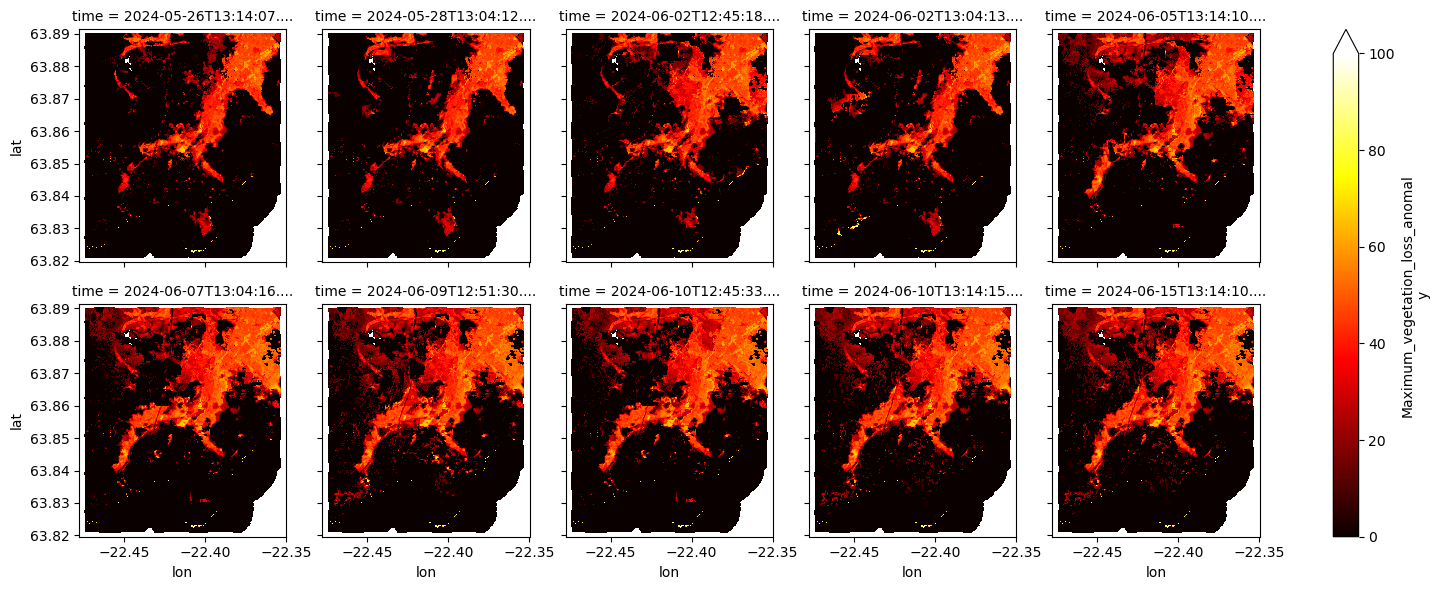

In [51]:
# Visualize lava flow time series
vam.rio.clip([aoi_projected], raster_crs).plot(col='time', y='lat', x='lon', col_wrap=5, vmin=0, vmax=100, cmap='hot')

In [52]:
if vam["time"].dtype == "O":
    vam["time"] = [dt.replace(tzinfo=None) for dt in vam["time"].values]

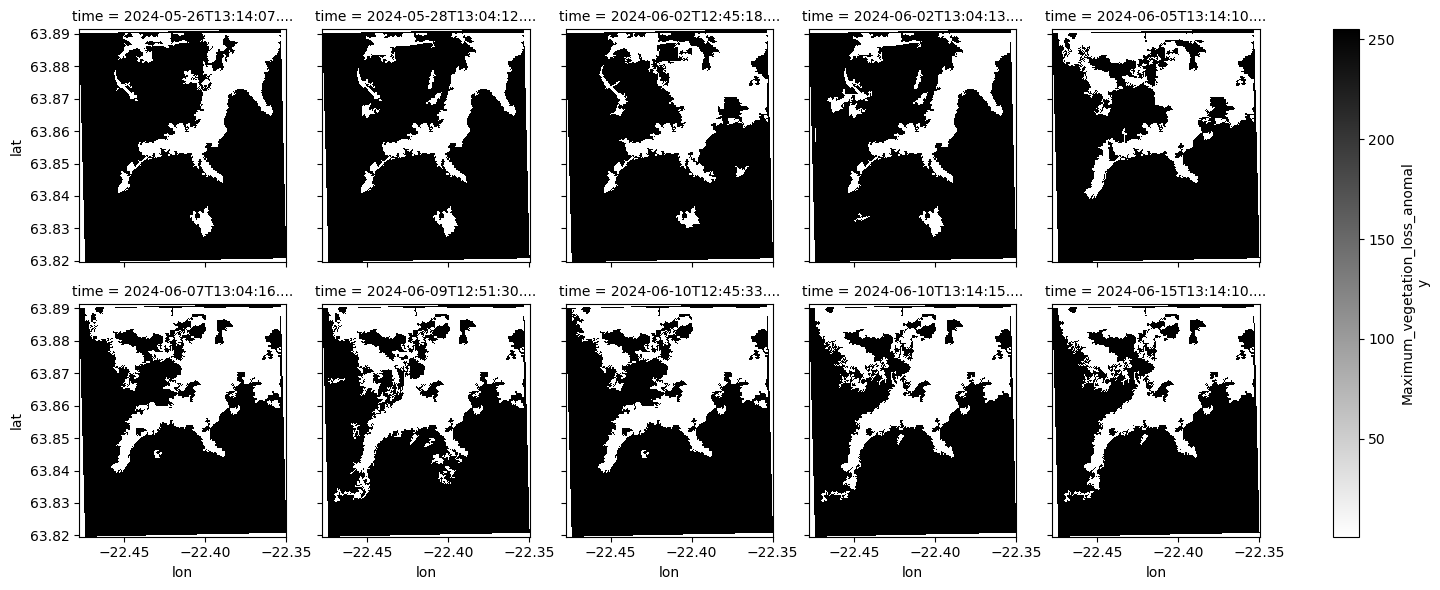

In [53]:
# Binarized flow map
b = binarize_flow(vam,40)
b.rio.clip([aoi_projected], raster_crs).plot(col='time', y='lat', x='lon', col_wrap=5,cmap="binary")

In [55]:
# Reference locations to mark on the final plot (lon, lat in EPSG:4326)
reference_locations = {
    "Sundhnúkur crater": {"lon": -22.396837418571245, "lat": 63.874219717299056, "marker": "^", "color": "cyan"},
    "Grindavik, Iceland": {"lon": -22.436076532623712, "lat":63.84331031548065, "marker": "s", "color": "lime"}
}

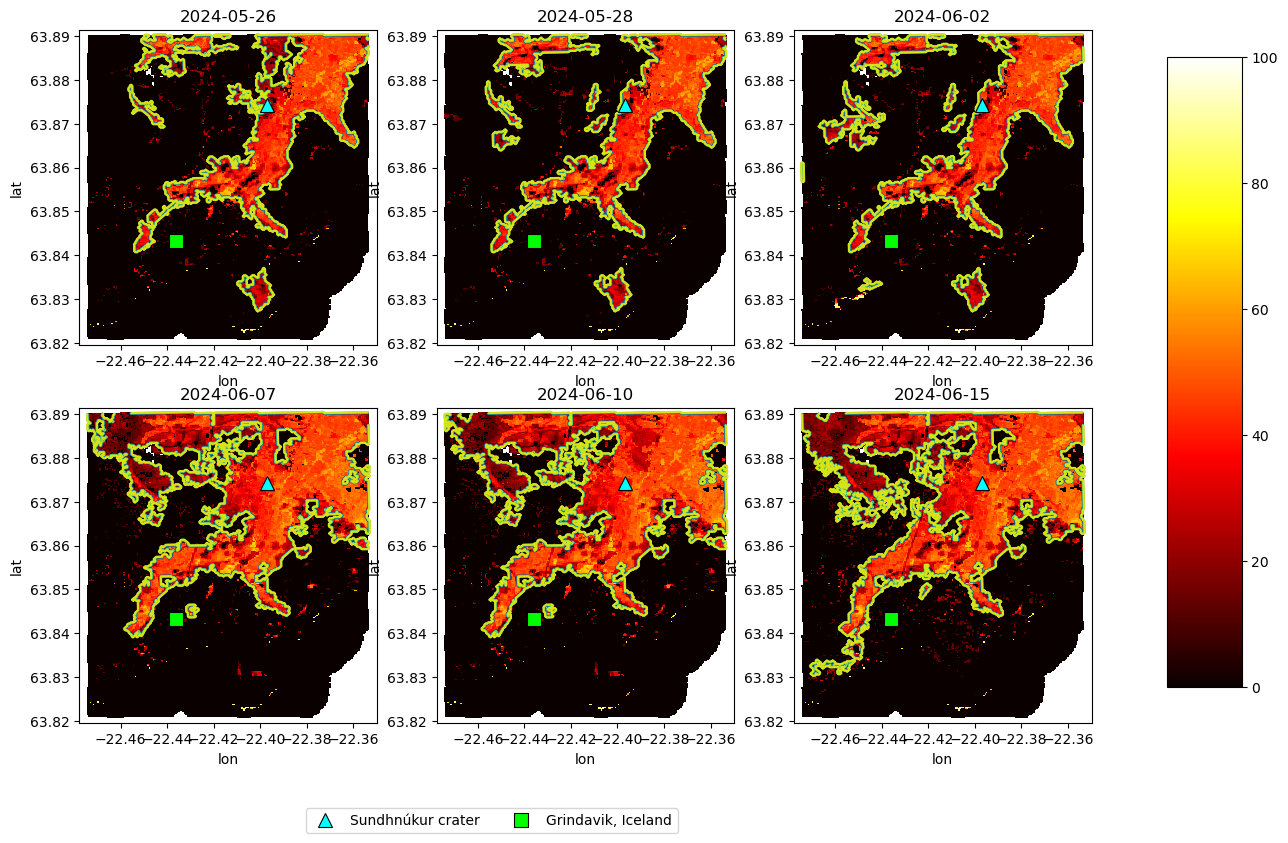

In [54]:
# Final time series image with truncated flow
vam_clipped = vam.rio.clip([aoi_projected], raster_crs)
b_clipped = b.rio.clip([aoi_projected], raster_crs)

n = vam_clipped.shape[0]

idx = np.linspace(0, n - 1, 6, dtype=int)

progression = vam_clipped[idx, :, :]
binarized = b_clipped[idx,:,:]
b_clipped[-1].rio.to_raster("iceland_final.tiff")

fig, axs = plt.subplots(2,3,figsize = (15,9))
axs = axs.flatten()
t = progression['time'].values
t = np.datetime_as_string(t)
for i in range(progression.sizes['time']):
    bar = progression[i,:,:].plot(ax=axs[i], y='lat', x='lon', cmap="hot", vmin=0, vmax=100,add_colorbar=False)
    binarized[i,:,:].plot.contour(ax=axs[i], y='lat', x='lon')

    # Capture the data extent before adding markers, so the markers don't cause
    # matplotlib to zoom out to fit them if they fall outside the raster extent.
    xlim = axs[i].get_xlim()
    ylim = axs[i].get_ylim()

    # Overlay reference locations (Sundhnukur crater, Svartsengi power station)
    for name, loc in reference_locations.items():
        axs[i].plot(
            loc["lon"], loc["lat"],
            marker=loc["marker"], color=loc["color"],
            markersize=10, markeredgecolor="black", markeredgewidth=0.8,
            linestyle="None", label=name,
        )

    # Restore the original zoom level (comment out these two lines if you'd
    # rather see the full extent that includes both reference points)
    axs[i].set_xlim(xlim)
    axs[i].set_ylim(ylim)

    axs[i].set_title(t[i][0:10])
    # progression[i,:,:].rio.to_raster(f"iceland_{i}.tiff")

# Shared legend for the reference locations (built from the last subplot's handles)
handles, labels = axs[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(reference_locations), bbox_to_anchor=(0.4, -0.02))

fig.subplots_adjust(right=0.8)
cbar_ax = fig.add_axes([0.85, 0.15, 0.05, 0.7])
fig.colorbar(bar, cax=cbar_ax)
plt.show()

## Part 3: Sulfur Dioxide Emissions Detection

In this part you will use data from the TROPOMI instrument aboard the European Copernicus Sentinel-5 Precursor satellite to visualize sulfur dioxide emissions from eruption activity. 

Read more about TROPOMI here: https://www.tropomi.eu/ 

<h3>Step 1: Import Packages & Define Functions</h3>

Run these cells to ensure necessary tools are downloaded and helper functions are defined for future use.

In [52]:
import geemap
from datetime import datetime
import openpyxl
import pandas as pd
import matplotlib.pyplot as plt
import netCDF4
import numpy as np
import xarray
from osgeo import gdal
import os
from skimage.measure import label, regionprops
from scipy.spatial.distance import pdist, squareform
!pip install gdal==3.6.4
from datetime import datetime
import glob
import matplotlib.image
from matplotlib import cm
!pip install opencv-python
import cv2
import rasterio as rs
from matplotlib import pyplot
import ipywidgets as widgets
import logging
logging.getLogger("rasterio").setLevel(logging.ERROR)
import ee

  Using cached gdal-3.6.4-cp314-cp314-linux_x86_64.whl
  Attempting uninstall: gdal
    Found existing installation: GDAL 3.12.2
    Uninstalling GDAL-3.12.2:
      Successfully uninstalled GDAL-3.12.2
  Using cached opencv_python-4.13.0.92-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
Using cached opencv_python-4.13.0.92-cp37-abi3-manylinux_2_28_x86_64.whl (72.9 MB)


In [53]:
def featurecollection_to_dataframe(fc, batch_size=5000):
    """Converti FeatureCollection in pandas DataFrame.
    Se piccola, usa getInfo().
    Se grande, esporta su Drive e leggi CSV.
    """
    # Proviamo con getInfo() prima
    try:
        features = fc.getInfo()['features']
        data = [f['properties'] for f in features]
        df = pd.DataFrame(data)
        return df
    except Exception as e:
        # Esporta su Drive
        task = ee.batch.Export.table.toDrive(
            collection=fc,
            description='export_temp',
            fileFormat='CSV'
        )
        task.start()

        # Attendi che il task finisca
        while task.active():
            print("In corso...")
            time.sleep(5)

        return None


def CountBands(image):
  return image.set('count',image.bandNames().length())

def InputPreparation(image):
  #selecting needed GLCM bands form inital 18 ones
  bands_glcm = ['glcm_contrast','glcm_corr','glcm_var','glcm_savg']
  #bands used for Classification + select(add) bands from glcm
  bands = ee.List(['SO2_column_number_density','so2_15km','sd','entropy']).cat(ee.List(bands_glcm))

  # Kernel for Stdv and entropy
  bigKernel = ee.Kernel.square(
      radius = 4,
      units = 'pixels')

  #Kernel for Convolution
  l3 = [-0.4444,-0.4444, -0.1111, -0.4444,-0.4444]

  #Center of Kernel is zero
  c3 = [-0.1111, -0.1111,3.222, -0.1111,-0.1111]

  #Assemble a list of lists, the 9x9 kernel weights as a 2D matrix
  lists3 = [l3,l3,c3,l3,l3]
  kernel3 = ee.Kernel.fixed(5,5,lists3)

  #Kernel for focalMin/focalMax
  kernel = ee.Kernel.circle(radius = 2)

  ###First training image : '2022-07-27', '2022-07-28'
    #median to take average pixel value from remaning images of collection, multiply to convert into dobson unit
  SO2_at_1km = image.select('SO2_column_number_density').multiply(10000/4.4615)\

  SO2_at_15km = image.select('SO2_column_number_density_15km').multiply(10000/4.4615)\

  #Compute standard derivation (Texture)
  sd = SO2_at_1km.reduceNeighborhood(
   reducer= ee.Reducer.stdDev(),
   kernel= bigKernel
   ).reproject('EPSG:4326',None,3500)

  #Compute Entropy (Texture)
  intso2=SO2_at_1km.multiply(10000).int()
  entropy=intso2.entropy(bigKernel).reproject('EPSG:4326',None,3500)

  #Compute Graylevel Co-occurence matrix
  glcm = intso2.rename('glcm').glcmTexture(size= 1).reproject('EPSG:4326',None,3500).select(bands_glcm)#vor select!
  sd1 = sd.unmask(-100);
  entropy1 = entropy.unmask(-100);
  glcm1 = glcm.unmask(-100);

  input = SO2_at_1km.unmask(-100).rename('SO2_column_number_density').addBands(SO2_at_15km.rename('so2_15km')).addBands(sd1.rename('sd')).addBands(entropy1.rename('entropy')).addBands(glcm1)

  input = input.set('name',image.get('name')).set('Date', image.get('Date')).set('system:time_start', image.get('system:time_start'))

  date=image.get('system:time_start')
  start = ee.Date(date)
  end = start.advance(1, 'day');
  dataset =ee.ImageCollection('COPERNICUS/S5P/NRTI/L3_CLOUD').filterDate(start,end).filterBounds(study_zone).select('cloud_top_height').max().unmask(-100)
  return image.select('SO2_column_number_density').rename('in').addBands(input).addBands(dataset.rename('altitude')).addBands(SO2_at_1km.rename('input'))

def fromgeecollectiontonumpy(ee_object,out_dir,scale=None, crs=None, region=None, file_per_band=False
):
    """Exports an ImageCollection as GeoTIFFs.

    Args:
        ee_object (object): The ee.Image to download.
        out_dir (str): The output directory for the exported images.
        scale (float, optional): A default scale to use for any bands that do not specify one; ignored if crs and crs_transform is specified. Defaults to None.
        crs (str, optional): A default CRS string to use for any bands that do not explicitly specify one. Defaults to None.
        region (object, optional): A polygon specifying a region to download; ignored if crs and crs_transform is specified. Defaults to None.
        file_per_band (bool, optional): Whether to produce a different GeoTIFF per band. Defaults to False.
    """

    if not isinstance(ee_object, ee.ImageCollection):
        print("The ee_object must be an ee.ImageCollection.")
        return

    if not os.path.exists(out_dir):
        os.makedirs(out_dir)

    try:

        count = int(ee_object.size().getInfo())
        print(f"Total number of images: {count}\n")
        print(f"Processing:")
        img_stack = []
        for i in range(0, count):
            image = ee.Image(ee_object.toList(count).get(i))
            image_array = geemap.ee_to_numpy(image.select('classification','SO2corrected'), region) # Client side
            img_stack.append(image_array)

        # Normalize array shapes and get min shape across all arrays (height, width)
        min_h = min(arr.shape[0] for arr in img_stack)
        min_w = min(arr.shape[1] for arr in img_stack)

        # Crop or pad each array to (min_h, min_w)
        normalized_stack = []
        for arr in img_stack:
            h, w = arr.shape[:2]
            # Crop larger arrays
            arr_cropped = arr[:min_h, :min_w, ...]
            # Pad smaller ones if needed (not strictly necessary here)
            if h < min_h or w < min_w:
                pad_h = min_h - h
                pad_w = min_w - w
                arr_cropped = np.pad(arr_cropped,((0, pad_h), (0, pad_w), (0, 0)),mode='constant',constant_values=np.nan,)
            normalized_stack.append(arr_cropped)
        return normalized_stack

    except Exception as e:
        print(e)

def apply_classifier(image3,ee_classifier):
  alt=image3.select('altitude')
  image2=image3.select(['SO2_column_number_density','so2_15km','sd','entropy','glcm_contrast','glcm_corr','glcm_var','glcm_savg']);
  image=image2.subtract(means).divide(std)
  so2_plume_15km=image3.select('so2_15km');
  so2_plume=image3.select('SO2_column_number_density')
  so2_median_density = so2_plume.unmask(-100);
  so2_classify_mask = image.classify(ee_classifier)
  so2_classify = so2_median_density.updateMask(so2_classify_mask)

  # Post-treatment : Apply a closing (dilatation = focalMax then erosion = focalMin)
  # Define a circle kernel of 1 pixel radius (adjust if needed, try 1.5)
  kernel = ee.Kernel.circle(
      radius = 1,
      units = 'pixels')
  connectivity=50;
  #Closing is better than opening to fullfil the plume and then apply PixelCount
  #2 iterations of dilatation and 3 of erosion seems to give the best results (adjust if needed)
  closed = so2_classify_mask.focalMax(
   kernel= kernel,
   iterations= 2).focalMin(
   kernel= kernel,
   iterations= 3).reproject('EPSG:4326',None,3500);
  so2_closed = so2_median_density.updateMask(closed)

  # Connectivity condition : to delete isolated pixels and keep only pixels part of the plume
  # ConnectedPixelCount returns a connection score of the SO2-positive pixels
  connexions = closed.selfMask().connectedPixelCount(ee.Number(connectivity).add(1)).reproject('EPSG:4326',None,3500);
  proxy = 0
  connexions = connexions.unmask(proxy)

  # Only keep the pixels that have a connectivity high enough
  # Score connectivity of 80 seems to be a good value, adjust if needed
  groupesPixels = connexions.gt(connectivity);
  positive_pixel = groupesPixels.reproject('EPSG:4326',None,3500);

  # Update the mask to the so2 map
  so2_plume = so2_median_density.updateMask(positive_pixel)
  # Update the mask to the so2 map
  so2_plume_15km = image.select('so2_15km').updateMask(positive_pixel)

  m2=positive_pixel.multiply(alt)
  m3=m2.updateMask(m2.gt(-100));
  mmean=ee.Image(ee.Number(m2.reduceRegion(reducer= ee.Reducer.max(),geometry= study_zone,scale= res,maxPixels= 1e13).values().get(0)));
  altcorreted=(positive_pixel.multiply(alt)).selfMask();
  m=m2.where(m2.eq(-100),mmean)
  flag=(so2_plume_15km.subtract(so2_plume)).multiply(m.subtract(10000)).divide(9000).add(so2_plume_15km);
  so2_corrected=so2_plume_15km.where(so2_plume.gte(0),flag.where(m.gt(10000),so2_plume_15km)).multiply(4.4615/10000).multiply(ee.Image.pixelArea()).multiply(0.000001*64*0.001)#
  st2=ee.Geometry.Polygon([[[158.6128787089055, 55.34598773699004],[158.6128787089055, 53.8505541387213],[164.4246462870305, 53.8505541387213],[164.4246462870305, 55.34598773699004]]])#, null, false);
  so2_original=so2_plume_15km#

  # Convert VCD from DU to mol/m2 (1DU=4.4615*10^-4mol/m2)
  kton=so2_corrected.reduceRegion(
          reducer= ee.Reducer.sum(),
          geometry= so2_corrected.geometry(),
          scale= res,
          maxPixels= 1e13
  ).values().get(0);

  output = image3.select('in').addBands(so2_plume).addBands(so2_plume_15km).addBands(positive_pixel.rename('classification')).addBands(m.selfMask().rename('masked_alt')).addBands(so2_original.rename('input')).addBands(image3.select('altitude')).addBands(so2_corrected.rename('SO2corrected')).set('name',image3.get('name')).set('kton',kton).set('Date', image3.get('Date')).set('system:time_start', image3.get('system:time_start'))

      #m.rename('masked_alt')).addBands(so2_corrected.rename('SO2corrected')).addBands(alt.rename('altitude'))
      #.set('kton',kton).set('Total_mass_corrected',total_mass111).set('Total_mass_1km',total_mass1).set('Total_mass_15km',total_mass15)//.addBands(ee.Image.constant(total_mass).rename('Total_mass'))

  return output
  #return classified.set('system:time_start', image.get('system:time_start'))

# Function to generate a list of the dates of the time series
def dayOffset(day):
  return startDate.advance(day, 'day')

def generateDateList(startDate, endDate):
  #Calculate the date range in milliseconds
  timeDiff = endDate.millis().subtract(startDate.millis());
  #Convert the difference in days
  daysDiff = timeDiff.divide(1000 * 60 * 60 * 24);
  dateList = ee.List.sequence(0, daysDiff.toInt());
  #Calculate the date from the startDate
  dateRange = dateList.map(dayOffset);
  return dateRange;

def One_image_per_dayfun(date):
    start = ee.Date(date)
    end = start.advance(1, 'day')

    filtered = raw.filterDate(start, end).filterBounds(study_zone)
    first_image = filtered.first()

    # Se non c'è immagine, ritorna un'immagine vuota (nulla)
    return ee.Algorithms.If(
        first_image,
        filtered \
            .select(['SO2_column_number_density', 'SO2_column_number_density_15km']) \
            .median() \
            .clip(study_zone) \
            .set('system:time_start', first_image.get('system:time_start')) \
            .set('name', ee.Date(first_image.get('system:time_start')).format('dd-MM-YYYY'))\
            .set('Date', ee.Date(first_image.get('system:time_start')).format('dd/MM/YYYY')),
        None
    )
def add_time_dim(xda):
     xda = xda.expand_dims(time = [datetime(2024,12,1)])
     return xda

Failed to reload module 'osgeo.ogr' from file '/srv/conda/envs/notebook/lib/python3.14/site-packages/osgeo/ogr.py'
Traceback (most recent call last):
  File "/srv/conda/envs/notebook/lib/python3.14/site-packages/IPython/extensions/autoreload.py", line 325, in check
    superreload(m, reload, self.old_objects)
    ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/srv/conda/envs/notebook/lib/python3.14/site-packages/IPython/extensions/autoreload.py", line 584, in superreload
    module = reload(module)
  File "/srv/conda/envs/notebook/lib/python3.14/importlib/__init__.py", line 129, in reload
    _bootstrap._exec(spec, module)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^
  File "<frozen importlib._bootstrap>", line 869, in _exec
  File "<frozen importlib._bootstrap_external>", line 759, in exec_module
  File "<frozen importlib._bootstrap>", line 491, in _call_with_frames_removed
  File "/srv/conda/envs/notebook/lib/python3.14/site-packages/osgeo/ogr.py", line 544, in <module>
    class Driver(Majo

<h3>Step 2: Set up Google Earth Engine and define volcano of interest</h3>

Run the first cell to use VICTOR login credentials to access Google Earth Engine. Then, run the next cell to select date, time, and location parameters.

In [54]:
# Use VICTOR credentials to log into Google Earth Engine

#insert your GOOGLE EARTH ENGINE project name, @title GOOGLE AND GOOGLE EARTH ENGINE ACCOUNT { run: "auto", form-width: "50%" }
ee_project_name = 'victor-397520' #@param {type: "string"}

path='/home/jovyan/TROPOMI_RF'#@param {type: "string"}

In [55]:
#@title Insert dates of interest and volcano coordinates { run: "auto", form-width: "50%" }

start_day = "2024-5-28" #@param {type: "date"}
end_day = "2024-6-05" #@param {type: "date"} #6/21 is the date sam has for remote sensing 

volcano_name = 'Sundhnúkur' #@param {type: "string"}
latitude =  63.8 #@param {type: "raw"}
longitude =  -22 #@param {type: "raw"} [-22.6,-21.9,63.7, 63.9]
radius =  60000#@param {type: "raw"}

### Step 3: Access Google Earth Engine and run the search

Run these cells to search for sulfur dioxide emissions data in your selected region and time period using Google Earth Engine.

In [56]:
# Access Google Earth Engine

# Trigger the authentication flow.
# ee.Authenticate()
# Initialize the library.
# ee.Initialize(project=ee_project_name)
credentials = ee.ServiceAccountCredentials(
    email=' gee-runner@victor-397520.iam.gserviceaccount.com',
    key_file='./victor-397520-6e925130ead5.json'
)
ee.Initialize(credentials, project='victor-397520')

#Load the trained classifier and normalization coefficients*
assetId = 'projects/victor-corradinoclaudia/assets/RF_Tropomi'
means = ee.Image('projects/victor-corradinoclaudia/assets/means_tropomi');
std = ee.Image('projects/victor-corradinoclaudia/assets/std_tropomi');

In [57]:
# Run the search 

images_dir = os.path.join(path, volcano_name)
os.makedirs(images_dir, exist_ok=True)
print(f"-------------------------------")
print(volcano_name)
print(f"-------------------------------")
volcano = ee.Geometry.Point([longitude, latitude])
study_zone = volcano.buffer(radius)
startDate = ee.Date(start_day)
endDate = ee.Date(end_day)
raw = (
    ee.ImageCollection("COPERNICUS/S5P/NRTI/L3_SO2")
    .select("SO2_column_number_density", "SO2_column_number_density_15km")
    .filterBounds(study_zone)
    .filterDate(startDate, endDate.advance(1, "day"))
)
dateList = generateDateList(startDate, endDate)
One_image_per_day = ee.ImageCollection(dateList.map(One_image_per_dayfun)).map(
    CountBands
)
res = 1113.2
s5 = (
    One_image_per_day.filter(ee.Filter.eq("count", 2))
    .filter(ee.Filter.neq("Date", "23/03/2025"))
    .map(InputPreparation)
)

timestamps = One_image_per_day.aggregate_array("system:time_start").getInfo()
date_strings = [
    datetime.utcfromtimestamp(ts / 1000).strftime("%Y-%m-%d") for ts in timestamps
]

# Apply the model
ee_classifier = ee.Classifier.load(assetId)
classified = s5.map(lambda image: apply_classifier(image, ee_classifier))
ktonList = classified.aggregate_array("kton")

classified.sort("system:time_start")
# Lista di immagini
image_list = classified.toList(classified.size())

# Creazione file Excel
workbook = openpyxl.Workbook()
worksheet = workbook.active
worksheet.append(["Data", "kton", "kton_volcano"])

dates = []
values = []

# Estrazione valori in kton
for ii in range(image_list.size().getInfo()):
    image = ee.Image(image_list.get(ii))
    name = image.get("name").getInfo()
    image2 = image.addBands(
        (image.select("classification").where(1, 0))
        .paint(volcano.buffer(70000), 1)
        .rename("volcano")
    )
    name = image.get("name").getInfo()
    tif_path = f"{images_dir}/{name}.tif"
    
    if not os.path.exists(tif_path):
        geemap.ee_export_image(
            image2.select('SO2corrected', 'masked_alt', 'classification', 'volcano'),
            filename=tif_path, scale=res, region=study_zone, file_per_band=False
        )
    else:
        print(f"File already exists, skipping download: {name}.tif")
    
    raster = rs.open(tif_path, "r+")
    array = raster.read()
    image_array = array[3]
    im = array[0]
    mask = array[2]
    kernel2 = np.ones((60, 60), np.uint8)
    img_dilation = cv2.dilate(mask, kernel2, iterations=1)
    labeled_mask = label(np.squeeze(img_dilation))
    props = regionprops(labeled_mask)
    tot = np.squeeze(mask + image_array)
    kton2 = 0
    so2_corrected2 = np.zeros(np.shape(im))

    for ii in range(len(props) + 1):
        if np.max(tot * (labeled_mask == ii)) == 2:
            print("plume detected")
            mask_volcano = (labeled_mask == ii) * (mask)
            so2_corrected2 = im * mask_volcano
            kton2 = np.nansum(so2_corrected2)
            print(kton2)

    kton_value = image.get("kton").getInfo()
    kton_value2 = kton2
    date_value = image.get("Date").getInfo()
    worksheet.append([name, kton_value, kton_value2])
    print(f"Data: {name}, kton_total: {kton_value}, kton_volcano: {kton_value2}")
    dates.append((datetime.strptime(date_value, "%d/%m/%Y")))
    values.append((kton_value))
    with rs.open(f"{images_dir}/{name}.tif", "r+") as update:
        update.write(so2_corrected2, 4)
# Salvataggio file
file_name = f"{images_dir}/kton_dati.xlsx"
workbook.save(file_name)

print("Data saved in:", file_name)


-------------------------------
Sundhnúkur
-------------------------------
Generating URL ...
Please wait ...
Data downloaded to /home/jovyan/TROPOMI_RF/Sundhnúkur/28-05-2024.tif


Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.


Data: 28-05-2024, kton_total: 0, kton_volcano: 0
Generating URL ...
Please wait ...
Data downloaded to /home/jovyan/TROPOMI_RF/Sundhnúkur/29-05-2024.tif
plume detected
0.7260363653342299


Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.


Data: 29-05-2024, kton_total: 0.7260363653342304, kton_volcano: 0.7260363653342299
Generating URL ...
Please wait ...
Data downloaded to /home/jovyan/TROPOMI_RF/Sundhnúkur/30-05-2024.tif
plume detected
0.3144048041742743


...

Data: 03-06-2024, kton_total: 1.14623032313648, kton_volcano: 1.1545648094919976
Generating URL ...
Please wait ...
Data downloaded to /home/jovyan/TROPOMI_RF/Sundhnúkur/04-06-2024.tif
plume detected
0.007798721578614033


Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.


Data: 04-06-2024, kton_total: 0.0076785940233566686, kton_volcano: 0.007798721578614033
Generating URL ...
Please wait ...
Data downloaded to /home/jovyan/TROPOMI_RF/Sundhnúkur/05-06-2024.tif
plume detected
0.03647483982413526


Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.


Data: 05-06-2024, kton_total: 0.03640059369661724, kton_volcano: 0.03647483982413526
Data saved in: /home/jovyan/TROPOMI_RF/Sundhnúkur/kton_dati.xlsx


<h3>Step 4: Visualize results</h3>

Run the following code to visualize sulfur dioxide emissions across your chosen time period.

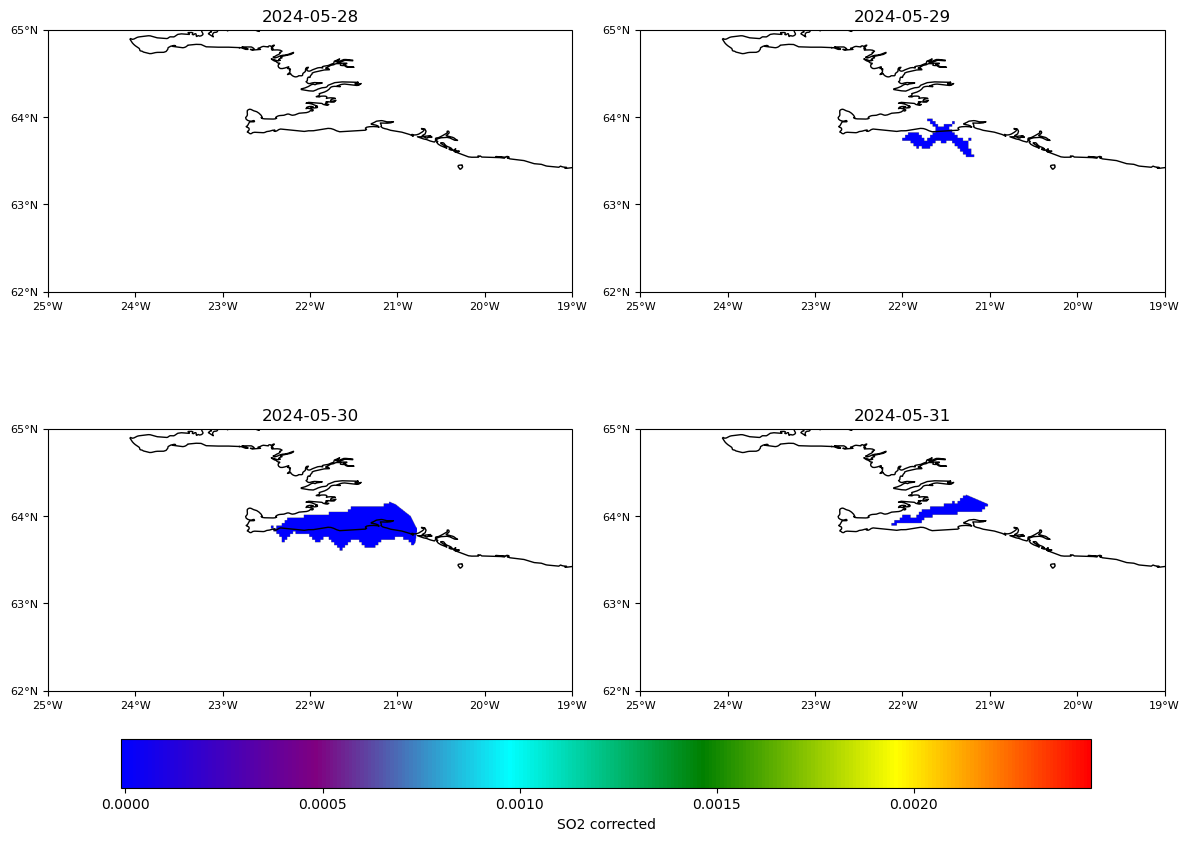

In [58]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import requests
from PIL import Image
from io import BytesIO
import cartopy.crs as ccrs
import numpy as np
import cartopy.mpl.ticker as cticker

images = classified.select('SO2corrected').toList(4)

fig, axes = plt.subplots(
    2, 2, figsize=(12, 10),
    subplot_kw={'projection': ccrs.PlateCarree()}
)

for i, ax in enumerate(axes.flatten()):
    img = ee.Image(images.get(i))
    
    url = img.getThumbURL({
        'min': -1.0744175204212435e-05,
        'max': 2.450277943651077,
        'palette': ['blue', 'purple', 'cyan', 'green', 'yellow', 'red'],
        'dimensions': 512,
        'region': img.geometry().bounds().getInfo()['coordinates']
    })
    
    response = requests.get(url)
    im = Image.open(BytesIO(response.content))

    # Get bounding box
    bounds = img.geometry().bounds().getInfo()['coordinates'][0]
    lons = [pt[0] for pt in bounds]
    lats = [pt[1] for pt in bounds]

    ax.imshow(
        im,
        extent=[min(lons), max(lons), min(lats), max(lats)],
        transform=ccrs.PlateCarree()
    )

    ax.coastlines()
    ax.add_feature(cfeature.BORDERS, linestyle=':')
    date = ee.Date(img.get('system:time_start')).format('YYYY-MM-dd').getInfo()
    ax.set_title(date)
    # Set extent first (important for consistent ticks)
    ax.set_extent([-25, -19, 62, 65], crs=ccrs.PlateCarree())
    
    # Define tick locations
    xticks = np.linspace(-25, -19, 7)
    yticks = np.linspace(62, 65, 4)
    
    ax.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax.set_yticks(yticks, crs=ccrs.PlateCarree())
    
    # Format nicely
    ax.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    
    ax.tick_params(labelsize=8)
    
    # Optional: only show left/bottom labels (cleaner)
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')

plt.tight_layout()
import matplotlib as mpl

# Create colormap from your palette
cmap = mpl.colors.LinearSegmentedColormap.from_list(
    "custom",
    ['blue', 'purple', 'cyan', 'green', 'yellow', 'red']
)

norm = mpl.colors.Normalize(
    vmin=-1.0744175204212435e-05,
    vmax=0.002450277943651077
)

# Create a ScalarMappable
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

# Add colorbar
cbar = fig.colorbar(
    sm,
    ax=axes,
    orientation='horizontal',
    fraction=0.05,
    pad=0.05
)

cbar.set_label('SO2 corrected')

plt.show()